### Sprachmodelle

[In Google Colab öffnen](https://colab.research.google.com/github/ktheu/InfoKursN/blob/main/neuronaleNetze6/inhalte/sprachmodelle.ipynb)

Programme wie ChatGPT beruhen auf **großen Sprachmodellen** (Large Language Models, LLMs). Ihr Kern ist erstaunlich
einfach: Ein neuronales Netz bekommt einen Text und sagt voraus, welches Stück Text als nächstes kommt. Hängt man die
Vorhersage an und wiederholt das, entsteht Wort für Wort ein neuer Text.

Wir bauen das im Kleinen nach: ein Modell, das **neue Vornamen erfindet**, Buchstabe für Buchstabe. Schritt für
Schritt wird das Modell besser:

1. Buchstabenpaare zählen (Bigramm-Modell),
2. dasselbe als neuronales Netz,
3. Embeddings und mehr Kontext,
4. Attention, der Mechanismus der großen Sprachmodelle.

Danach geht es um Tokens, Transformer und die Grenzen großer Sprachmodelle. Das Notebook läuft in Google Colab
(Hinweise im Notebook PyTorch und Bildklassifikation). Eine GPU ist nicht nötig.

In [1]:
import math
import os
import random
import time
import urllib.request

import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

print('PyTorch', torch.__version__)

PyTorch 2.14.1+cpu


#### Die Daten

Die Namensliste enthält alle Vornamen, die 2023 in Köln an Neugeborene vergeben wurden und nur aus Buchstaben
bestehen (Quelle: Stadt Köln, Offene Daten Köln, Datenlizenz Deutschland Zero 2.0). Liegt die Datei nicht neben dem
Notebook (z.B. in Colab), wird sie heruntergeladen.

In [2]:
datei = 'vornamen.txt'
if not os.path.exists(datei):
    urllib.request.urlretrieve('https://raw.githubusercontent.com/ktheu/InfoKursN/main/neuronaleNetze6/inhalte/vornamen.txt', datei)
namen = open(datei, encoding='utf-8').read().split()

print(len(namen), 'Namen')
print(namen[:8])
print('mittlere Länge:', round(sum(len(n) for n in namen) / len(namen), 2))

4865 Namen
['aadhya', 'aadit', 'aahan', 'aaleyah', 'aaliya', 'aaliyah', 'aaren', 'aaron']
mittlere Länge: 5.69


Das Modell arbeitet mit einzelnen Zeichen. Jedes Zeichen bekommt eine Nummer. Ein zusätzliches Zeichen `.` markiert
Anfang und Ende eines Namens. Aus „lea“ wird so `.lea.`, und das Modell lernt, dass nach dem Anfang z.B. ein `l`
kommen kann und nach `a` oft das Ende.

In [3]:
zeichen = ['.'] + sorted(set(''.join(namen)))
nr = {z: i for i, z in enumerate(zeichen)}
anzahl = len(zeichen)
print(anzahl, ''.join(zeichen))

random.seed(0)
random.shuffle(namen)
grenze = int(0.9 * len(namen))
train, test = namen[:grenze], namen[grenze:]
print(len(train), 'Trainingsnamen,', len(test), 'Testnamen')

30 .abcdefghijklmnopqrstuvwxyzäöü
4378 Trainingsnamen, 487 Testnamen


Wie im Notebook PyTorch und Bildklassifikation halten wir Testdaten zurück: 10 Prozent der Namen sieht das Modell
beim Lernen nicht.

### Das Bigramm-Modell: Paare zählen

Die einfachste Idee: Wir zählen in allen Trainingsnamen, wie oft auf ein Zeichen ein anderes folgt. Ein solches Paar
heißt **Bigramm**.

In [4]:
N = torch.zeros(anzahl, anzahl)
for name in train:
    s = '.' + name + '.'
    for a, b in zip(s, s[1:]):
        N[nr[a], nr[b]] += 1

paare = sorted(((N[i, j].item(), zeichen[i] + zeichen[j]) for i in range(anzahl) for j in range(anzahl)), reverse=True)
print(paare[:10])

[(1314.0, 'a.'), (783.0, 'an'), (637.0, 'n.'), (531.0, '.a'), (465.0, 'li'), (462.0, 'na'), (456.0, '.m'), (438.0, 'ar'), (420.0, 'in'), (420.0, 'e.')]


Am häufigsten ist `a.`: Viele Namen enden auf a. In der Tabelle sieht man alle Paare auf einmal. Zeile ist das
aktuelle Zeichen, Spalte das nächste, je dunkler, desto häufiger:

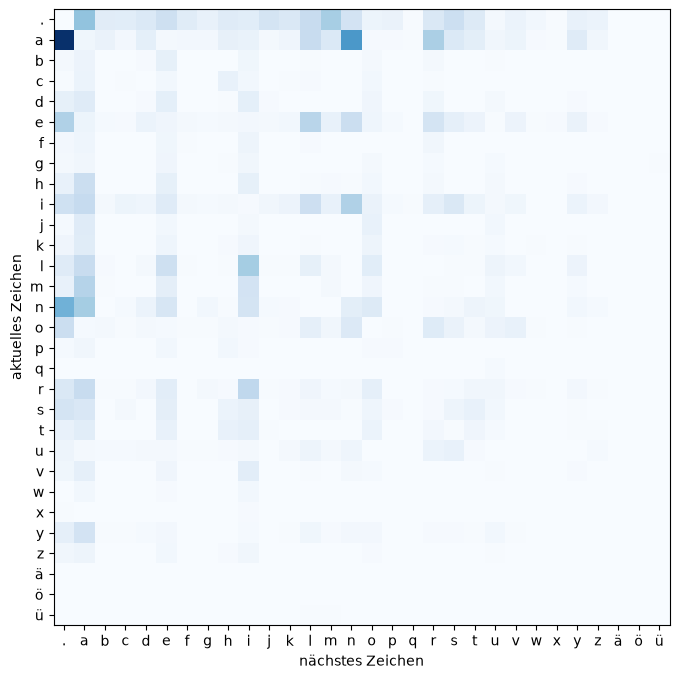

In [5]:
plt.figure(figsize=(8, 8))
plt.imshow(N, cmap='Blues')
plt.xticks(range(anzahl), zeichen)
plt.yticks(range(anzahl), zeichen)
plt.xlabel('nächstes Zeichen')
plt.ylabel('aktuelles Zeichen')
plt.show()

Aus den Zählungen werden Wahrscheinlichkeiten: Jede Zeile wird durch ihre Summe geteilt. Vorher addieren wir zu
jeder Zählung 1. Sonst hätte ein Paar, das in den Trainingsnamen nie vorkommt, die Wahrscheinlichkeit 0, und das
Modell könnte einen Testnamen mit diesem Paar gar nicht erklären.

In [6]:
P = (N + 1) / (N + 1).sum(dim=1, keepdim=True)

zeile = P[nr['a']]
beste = zeile.argsort(descending=True)[:5]
print('nach a:', [(zeichen[i], round(zeile[i].item(), 3)) for i in beste.tolist()])

nach a: [('.', 0.299), ('n', 0.179), ('r', 0.1), ('l', 0.072), ('m', 0.041)]


Nach einem `a` endet der Name mit Wahrscheinlichkeit 0.30, sonst folgt am ehesten `n`, `r` oder `l`.

**Namen erzeugen:** Wir beginnen mit `.`, würfeln das nächste Zeichen mit den Wahrscheinlichkeiten der Zeile aus,
dann das übernächste mit den Wahrscheinlichkeiten seiner Zeile, bis `.` gewürfelt wird. `torch.multinomial` würfelt
mit vorgegebenen Wahrscheinlichkeiten.

In [7]:
def erzeuge_bigramm(P, anzahl_namen, seed=1):
    g = torch.Generator().manual_seed(seed)
    ergebnis = []
    for i in range(anzahl_namen):
        aktuell, name = 0, ''
        while True:
            aktuell = torch.multinomial(P[aktuell], 1, generator=g).item()
            if aktuell == 0:
                break
            name += zeichen[aktuell]
        ergebnis.append(name)
    return ergebnis

print(erzeuge_bigramm(P, 12))

['n', 'tessintan', 't', 'liy', 'o', 'ma', 'pevabigofa', 'fus', 'xäin', 'e', 'u', 'ya']


Manche Ergebnisse klingen wie Namen, die meisten nicht. Das Modell kennt immer nur das letzte Zeichen und vergisst
alles davor.

#### Wie gut ist das Modell?

Wir messen es wie in den anderen Notebooks mit der **Cross-Entropy**: dem negativen Logarithmus der
Wahrscheinlichkeit, die das Modell dem tatsächlich folgenden Zeichen gibt, gemittelt über alle Zeichen. Beispiel
„anna“:

In [8]:
def wahrscheinlichkeiten(name, P):
    s = '.' + name + '.'
    return [(a + b, P[nr[a], nr[b]].item()) for a, b in zip(s, s[1:])]

w = wahrscheinlichkeiten('anna', P)
print([(paar, round(p, 4)) for paar, p in w])
print('mittlerer Fehler:', round(sum(-math.log(p) for _, p in w) / len(w), 4))

def fehler_bigramm(liste, P):
    werte = [-math.log(p) for name in liste for _, p in wahrscheinlichkeiten(name, P)]
    return sum(werte) / len(werte)

print('Training:', round(fehler_bigramm(train, P), 4), ' Test:', round(fehler_bigramm(test, P), 4))
print('Raten:', round(math.log(anzahl), 4))

[('.a', 0.1207), ('an', 0.1785), ('nn', 0.0586), ('na', 0.2055), ('a.', 0.2994)]
mittlerer Fehler: 1.8926
Training: 2.4718  Test: 2.5198
Raten: 3.4012


Würde das Modell einfach raten (jedes der 30 Zeichen mit Wahrscheinlichkeit $\frac{1}{30}$), wäre der Fehler
$\ln 30 \approx 3.40$. Das Bigramm-Modell schafft 2.52 auf den Testnamen. Dieser Wert ist die Messlatte für die
neuronalen Netze.

### Das Bigramm-Modell als neuronales Netz

Dasselbe Modell lässt sich als neuronales Netz bauen. Input ist das aktuelle Zeichen als **One-Hot-Vektor**: 30
Zahlen, alle 0, nur an der Stelle des Zeichens eine 1. Eine Schicht `nn.Linear(30, 30)` ohne Bias macht daraus 30
Logits, Softmax macht daraus Wahrscheinlichkeiten für das nächste Zeichen.

Multipliziert man einen One-Hot-Vektor mit der Gewichtsmatrix, wählt man einfach eine Zeile aus. Die Gewichtsmatrix
spielt also die Rolle der Zähltabelle, nur dass das Netz die Werte durch Gradientenabstieg lernt.

In [9]:
def daten(liste, kontext):
    X, Y = [], []
    for name in liste:
        fenster = [0] * kontext
        for z in name + '.':
            X.append(fenster)
            Y.append(nr[z])
            fenster = fenster[1:] + [nr[z]]
    return torch.tensor(X), torch.tensor(Y)

X_train, Y_train = daten(train, 1)
X_test, Y_test = daten(test, 1)
print(X_train.shape, X_train[:6, 0].tolist(), Y_train[:6].tolist())
print(F.one_hot(X_train[:2, 0], anzahl))

torch.Size([29297, 1])

 [0, 14, 9, 1, 14, 0] [14, 9, 1, 14, 0, 19]
tensor([[1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
         0, 0, 0, 0, 0, 0],
        [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0,
         0, 0, 0, 0, 0, 0]])


Aus jedem Namen werden mehrere Beispiele: Input ist das aktuelle Zeichen, Ziel das nächste. Aus 4378 Trainingsnamen
werden so 29297 Beispiele.

In [10]:
torch.manual_seed(0)
bigramm_netz = nn.Linear(anzahl, anzahl, bias=False)
optimizer = torch.optim.Adam(bigramm_netz.parameters(), lr=0.1)
xs = F.one_hot(X_train[:, 0], anzahl).float()

for schritt in range(301):
    loss = F.cross_entropy(bigramm_netz(xs), Y_train)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    if schritt % 100 == 0:
        print(schritt, round(loss.item(), 4))

with torch.no_grad():
    test_loss = F.cross_entropy(bigramm_netz(F.one_hot(X_test[:, 0], anzahl).float()), Y_test)
print('Test:', round(test_loss.item(), 4))

0 3.4189


100 2.4654


200 2.4634


300 2.4627
Test: 2.517


Das Netz landet beim selben Fehler wie das Zählen. Es hat dieselben Wahrscheinlichkeiten gelernt, nur auf einem
anderen Weg. Der Vorteil des Netzes: Es lässt sich erweitern.

### Embeddings und mehr Kontext

Das Bigramm-Modell sieht nur ein Zeichen. Wollte man drei vorherige Zeichen zählen, bräuchte man eine Tabelle mit
$30^3 = 27000$ Zeilen, und die meisten Kombinationen kämen in den Namen nie vor.

Ein neuronales Netz geht anders vor (Yoshua Bengio und andere, 2003):

- Jedes Zeichen bekommt einen gelernten Vektor aus 10 Zahlen, sein **Embedding**. Zeichen, die sich ähnlich
  verhalten, sollen ähnliche Vektoren bekommen.
- Die Embeddings der letzten drei Zeichen werden hintereinander gehängt (30 Zahlen) und gehen in eine versteckte
  Schicht mit 200 Neuronen, dann in die Ausgabeschicht mit 30 Logits.

`nn.Embedding(30, 10)` ist eine Tabelle mit 30 Zeilen zu je 10 Zahlen. Für ein Zeichen liefert sie seine Zeile, das
ist dasselbe wie One-Hot-Vektor mal Gewichtsmatrix, nur schneller. Als Aktivierung nehmen wir hier `tanh`, eine
Sigmoid-ähnliche Funktion mit Werten zwischen $-1$ und 1.

In [11]:
class MLP(nn.Module):
    def __init__(self, kontext, emb=10, versteckt=200):
        super().__init__()
        self.emb = nn.Embedding(anzahl, emb)
        self.fc1 = nn.Linear(kontext * emb, versteckt)
        self.fc2 = nn.Linear(versteckt, anzahl)

    def forward(self, x):
        e = self.emb(x).reshape(x.shape[0], -1)
        return self.fc2(torch.tanh(self.fc1(e)))

def trainiere(modell, kontext, schritte=20000):
    X_train, Y_train = daten(train, kontext)
    X_test, Y_test = daten(test, kontext)
    optimizer = torch.optim.Adam(modell.parameters(), lr=0.003)
    start = time.time()
    for schritt in range(schritte):
        idx = torch.randint(0, X_train.shape[0], (64,))
        loss = F.cross_entropy(modell(X_train[idx]), Y_train[idx])
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    with torch.no_grad():
        f_train = F.cross_entropy(modell(X_train), Y_train).item()
        f_test = F.cross_entropy(modell(X_test), Y_test).item()
    print(f'Parameter {sum(p.numel() for p in modell.parameters())}  Training {f_train:.4f}  Test {f_test:.4f}  '
          f'({time.time() - start:.0f} s)')

torch.manual_seed(0)
mlp3 = MLP(3)
trainiere(mlp3, 3)

Parameter 12530  Training 2.0153  Test 2.3932  (30 s)


Jeder Trainingsschritt benutzt einen zufälligen Batch von 64 Beispielen. Mit drei Zeichen Kontext sinkt der Fehler
auf den Testnamen von 2.52 auf 2.39. Auf den Trainingsnamen ist er mit 2.02 deutlich kleiner: Das Modell hat sich
die Trainingsnamen schon ein Stück weit gemerkt.

Mehr Kontext ist nicht automatisch besser:

In [12]:
torch.manual_seed(0)
mlp5 = MLP(5)
trainiere(mlp5, 5)

Parameter 16530  Training 1.7543  Test 2.6121  (33 s)


Mit fünf Zeichen Kontext ist der Fehler auf den Trainingsnamen noch kleiner, auf den Testnamen aber größer (2.61).
Das ist **Overfitting**: Bei nur 4378 Trainingsnamen kann sich das Modell mit fünf Zeichen Kontext die Namen
auswendig merken. Große Sprachmodelle brauchen deshalb riesige Mengen an Trainingstext.

Die Namen, die das Modell mit drei Zeichen Kontext erfindet:

In [13]:
def erzeuge(modell, kontext, anzahl_namen, temperatur=1.0, seed=1):
    g = torch.Generator().manual_seed(seed)
    ergebnis = []
    with torch.no_grad():
        for i in range(anzahl_namen):
            fenster, name = [0] * kontext, ''
            while len(name) < 20:
                logits = modell(torch.tensor([fenster]))[0]
                p = torch.softmax(logits / temperatur, dim=0)
                z = torch.multinomial(p, 1, generator=g).item()
                if z == 0:
                    break
                name += zeichen[z]
                fenster = fenster[1:] + [z]
            ergebnis.append(name)
    return ergebnis

neu = erzeuge(mlp3, 3, 15)
print(neu)
print('davon in der Namensliste:', [n for n in neu if n in namen])

['nita', 'sinta', 'aveliy', 'lora', 'per', 'bastra', 'fus', 'fuin', 'emilov', 'antin', 'asironhar', 'füne', 'ser', 'nailima', 'mahar']
davon in der Namensliste: ['lora', 'emilov']


Die meisten klingen jetzt wie Namen, und viele davon gibt es in der Liste gar nicht.

#### Was die Embeddings gelernt haben

Jedes Zeichen ist jetzt ein Punkt in einem 10-dimensionalen Raum. Um ihn zu zeichnen, projizieren wir die Punkte auf
die zwei Richtungen, in denen sie am meisten streuen (Hauptkomponenten):

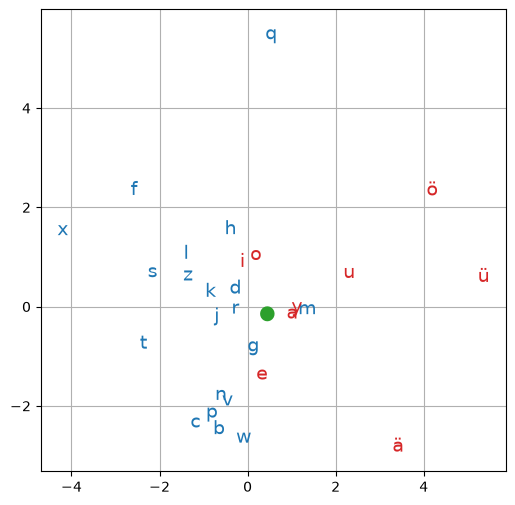

In [14]:
E = mlp3.emb.weight.detach()
E = E - E.mean(dim=0)
U, S, V = torch.linalg.svd(E, full_matrices=False)
xy = E @ V[:2].T

plt.figure(figsize=(6, 6))
for i, z in enumerate(zeichen):
    farbe = 'tab:red' if z in 'aeiouyäöü' else ('tab:green' if z == '.' else 'tab:blue')
    plt.text(xy[i, 0], xy[i, 1], '●' if z == '.' else z, fontsize=14, color=farbe, ha='center', va='center')
plt.xlim(xy[:, 0].min() - 0.5, xy[:, 0].max() + 0.5)
plt.ylim(xy[:, 1].min() - 0.5, xy[:, 1].max() + 0.5)
plt.grid()
plt.show()

Vokale sind rot, Konsonanten blau, der grüne Punkt ist das Zeichen für Anfang und Ende. Die Vokale stehen in der
Mitte und rechts, ä, ö, ü und u ganz rechts. Fast alle Konsonanten stehen links und unten, seltene wie q, x und f am
Rand. Ganz sauber getrennt sind die Gruppen nicht, und in zwei Dimensionen sieht man nur einen Teil der 10
Dimensionen. Niemand hat dem Modell aber gesagt, was ein Vokal ist. Es hat Embeddings gelernt, die für die
Vorhersage nützlich sind, und ähnlich gebrauchte Zeichen liegen dabei eher beieinander.

Große Sprachmodelle machen dasselbe mit Wörtern und Wortteilen. Ihre Embeddings haben tausende Dimensionen, und
Wörter mit ähnlicher Bedeutung liegen nahe beieinander.

#### Temperatur

Beim Würfeln kann man die Logits vorher durch eine **Temperatur** $T$ teilen. Bei $T < 1$ werden die großen
Wahrscheinlichkeiten noch größer, das Modell wählt fast immer das Wahrscheinlichste. Bei $T > 1$ werden die
Wahrscheinlichkeiten gleichmäßiger, das Ergebnis wird überraschender und fehlerhafter.

In [15]:
for t in [0.5, 1.0, 1.5]:
    print(t, erzeuge(mlp3, 3, 10, temperatur=t))

0.5

 ['nico', 'sina', 'matte', 'yuri', 'louiz', 'jamaderina', 'fain', 'elija', 'lucia', 'aria']
1.0 ['nita', 'sinta', 'aveliy', 'lora', 'per', 'bastra', 'fus', 'fuin', 'emilov', 'antin']
1.5 ['netessir', 'amat', 'loy', 'ommu', 'perb', 'dgheerius', 'xhin', 'egu', 'yona', 'lio']


Bei Chatbots kann man die Temperatur oft einstellen: niedrig für sachliche Antworten, höher für kreative Texte.

### Attention

Das MLP sieht ein festes Fenster von drei Zeichen, und jede Position im Fenster hat ihre eigenen Gewichte. Für lange
Texte ist das unbrauchbar: Ob ein Satz eine Frage ist, kann vom Wort am Anfang abhängen, das 20 Wörter zurückliegt.

**Attention** löst das so: Die aktuelle Position darf auf **alle** vorherigen Positionen schauen und selbst
entscheiden, wie wichtig jede davon gerade ist. Dazu bekommt jede Position drei Vektoren, die aus ihrem Embedding
berechnet werden:

- eine **Query** (Frage): Wonach suche ich?
- einen **Key** (Schlüssel): Was biete ich an?
- einen **Value** (Wert): Was gebe ich weiter, wenn ich gewählt werde?

Die Query der aktuellen Position wird mit jedem Key multipliziert (Skalarprodukt). Ein großes Produkt heißt: passt
gut. Softmax macht aus den Produkten Gewichte, die zusammen 1 ergeben. Das Ergebnis ist die gewichtete Summe der
Values. Ein Beispiel mit drei Positionen und zweidimensionalen Vektoren:

In [16]:
q = torch.tensor([1.0, 2.0])
K = torch.tensor([[1.0, 0.0],
                  [0.0, 1.0],
                  [1.0, 1.0]])
V = torch.tensor([[10.0, 0.0],
                  [0.0, 10.0],
                  [5.0, 5.0]])

scores = K @ q
gewichte = torch.softmax(scores, dim=0)
print('Scores:', scores)
print('Gewichte:', gewichte)
print('Ergebnis:', gewichte @ V)

Scores: tensor([1., 2., 3.])
Gewichte: tensor([0.0900, 0.2447, 0.6652])
Ergebnis: tensor([4.2265, 5.7735])


Die Scores sind $1 \cdot 1 + 2 \cdot 0 = 1$, $1 \cdot 0 + 2 \cdot 1 = 2$ und $1 + 2 = 3$. Die dritte Position passt am
besten zur Query und bekommt das größte Gewicht (0.67), die erste das kleinste (0.09). Das Ergebnis ist eine
Mischung der Values, in der die dritte Position am stärksten vertreten ist.

Query, Key und Value werden mit gelernten Gewichtsmatrizen aus den Embeddings berechnet. Das Netz lernt also selbst,
wonach jede Position fragen soll. Damit das Modell weiß, an welcher Stelle ein Zeichen steht, bekommt jede Position
zusätzlich ein eigenes gelerntes Embedding, das zum Zeichen-Embedding addiert wird. In der Formel teilt man die
Scores noch durch die Wurzel der Vektorlänge, damit die Softmax-Funktion nicht zu extrem wird.

Ein kleines Modell mit Attention über die letzten 8 Zeichen:

In [17]:
class AttentionModell(nn.Module):
    def __init__(self, kontext, emb=32):
        super().__init__()
        self.emb = nn.Embedding(anzahl, emb)
        self.pos = nn.Embedding(kontext, emb)
        self.query = nn.Linear(emb, emb, bias=False)
        self.key = nn.Linear(emb, emb, bias=False)
        self.value = nn.Linear(emb, emb, bias=False)
        self.fc1 = nn.Linear(emb, 128)
        self.fc2 = nn.Linear(128, anzahl)

    def forward(self, x):
        h = self.emb(x) + self.pos(torch.arange(x.shape[1]))
        q = self.query(h[:, -1:, :])
        k = self.key(h)
        v = self.value(h)
        gewichte = torch.softmax(q @ k.transpose(1, 2) / math.sqrt(k.shape[-1]), dim=-1)
        a = (gewichte @ v)[:, 0, :]
        return self.fc2(torch.relu(self.fc1(a)))

torch.manual_seed(0)
attention = AttentionModell(8)
trainiere(attention, 8)
print(erzeuge(attention, 8, 15))

Parameter 12382  Training 2.0644  Test 2.3338  (66 s)
['eltaysir', 'amar', 'loy', 'loma', 'perbeder', 'arios', 'fulia', 'gueli', 'anoko', 'asiroghar', 'faberina', 'khilima', 'mahar', 'ennre', 'roke']


Mit ähnlich vielen Parametern wie das MLP mit drei Zeichen ist das Attention-Modell auf den Testnamen am besten
(2.33). Es kann acht Zeichen zurückschauen, ohne für jede Position eigene Gewichte zu brauchen, und überfittet deshalb
weniger als das MLP mit fünf Zeichen.

| Modell | Fehler auf den Testnamen |
|---|---|
| Raten | 3.40 |
| Bigramm (Zählen oder Netz) | 2.52 |
| MLP, 3 Zeichen Kontext | 2.39 |
| MLP, 5 Zeichen Kontext | 2.61 |
| Attention, 8 Zeichen Kontext | 2.33 |

### Tokens

Große Sprachmodelle arbeiten weder mit einzelnen Zeichen noch mit ganzen Wörtern, sondern mit **Tokens**: häufigen
Wortteilen. Ein verbreitetes Verfahren dafür ist **Byte Pair Encoding** (BPE): Man beginnt mit einzelnen Zeichen und
verschmilzt immer wieder das häufigste Paar nebeneinander stehender Tokens zu einem neuen Token.

In [18]:
def bpe(woerter, anzahl_schritte):
    folgen = [list(w) for w in woerter]
    for schritt in range(anzahl_schritte):
        paare = {}
        for f in folgen:
            for a, b in zip(f, f[1:]):
                paare[(a, b)] = paare.get((a, b), 0) + 1
        a, b = max(paare, key=paare.get)
        print(f'{schritt + 1:2}: {a} + {b} -> {a + b}  ({paare[(a, b)]}-mal)')
        neu = []
        for f in folgen:
            g, i = [], 0
            while i < len(f):
                if i + 1 < len(f) and f[i] == a and f[i + 1] == b:
                    g.append(a + b)
                    i += 2
                else:
                    g.append(f[i])
                    i += 1
            neu.append(g)
        folgen = neu
    return folgen

ergebnis = bpe(namen, 12)
for w, f in zip(namen[:8], ergebnis[:8]):
    print(w, f)

 1: a + n -> an  (864-mal)
 2: l + i -> li  (512-mal)
 3: a + r -> ar  (473-mal)
 4: n + a -> na  (364-mal)
 5: l + e -> le  (306-mal)
 6: i + n -> in  (284-mal)
 7: l + a -> la  (275-mal)
 8: m + a -> ma  (252-mal)
 9: r + i -> ri  (247-mal)
10: r + a -> ra  (241-mal)
11: m + i -> mi  (240-mal)
12: e + n -> en  (231-mal)


nian ['n', 'i', 'an']
sabri ['s', 'a', 'b', 'ri']
kira ['k', 'i', 'ra']
ranali ['r', 'an', 'a', 'li']
pacino ['p', 'a', 'c', 'in', 'o']
tijana ['t', 'i', 'j', 'an', 'a']
fabian ['f', 'a', 'b', 'i', 'an']
carla ['c', 'ar', 'la']


Häufige Endungen und Silben werden zu eigenen Tokens. Große Sprachmodelle haben so einen Wortschatz von etwa
50000 bis 200000 Tokens. Häufige Wörter sind ein einziges Token, seltene Wörter werden in mehrere Teile zerlegt.
Deshalb kann ein Sprachmodell auch Wörter verarbeiten, die es nie gesehen hat.

### Große Sprachmodelle

Unser Attention-Modell hat ungefähr 12000 Parameter. Große Sprachmodelle funktionieren im Prinzip genauso, sind aber
um viele Größenordnungen größer:

- Sie beruhen auf dem **Transformer** (2017, Artikel *Attention Is All You Need*). Ein Transformer-Block besteht aus
  Attention und einer vollständig verbundenen Schicht. Jede Position stellt dabei ihre eigene Query, und es gibt
  viele Attention-Köpfe nebeneinander, die auf verschiedene Dinge achten. Dutzende solcher Blöcke werden
  übereinander gestapelt, verbunden mit Skip Connections wie bei ResNet.
- **GPT** heißt *Generative Pre-trained Transformer*. GPT-2 (2019) hatte 1,5 Milliarden Parameter, GPT-3 (2020) 175
  Milliarden.
- **Vortraining** (pre-training): Das Modell lernt an riesigen Textmengen aus dem Internet und aus Büchern, das
  nächste Token vorherzusagen, genau wie unser Namensmodell den nächsten Buchstaben. Dafür braucht man tausende GPUs
  über Wochen.
- **Feinabstimmung** (fine-tuning): Danach wird das Modell mit Beispielen für gute Antworten und mit Bewertungen
  durch Menschen weiter trainiert, damit es Fragen beantwortet und Anweisungen befolgt, statt nur Text fortzusetzen.
  So entstand 2022 ChatGPT.

Beim Antworten macht ein Chatbot dasselbe wie unsere Funktion `erzeuge`: Token vorhersagen, mit einer Temperatur
würfeln, anhängen, wiederholen.

#### Grenzen

- **Halluzinationen:** Ein Sprachmodell erzeugt Text, der wahrscheinlich klingt, nicht Text, der wahr ist. Wie unser
  Modell Namen erfindet, die es nicht gibt, erfindet ein großes Modell manchmal Fakten, Zitate oder Quellen, die
  überzeugend aussehen.
- **Wissensstand:** Das Modell kennt nur, was in seinen Trainingsdaten stand.
- **Verzerrungen** (bias): Vorurteile und Einseitigkeiten aus den Trainingsdaten können in den Antworten auftauchen.
- **Datenschutz und Urheberrecht:** Was man eingibt, kann gespeichert werden. Die Trainingsdaten stammen oft aus
  Texten, deren Autoren nicht gefragt wurden.
- **Energie:** Training und Betrieb großer Modelle brauchen sehr viel Strom.

Antworten eines Sprachmodells sollte man deshalb prüfen, besonders bei Fakten.

### Zusammenfassung

- Ein **Sprachmodell** sagt voraus, welches Zeichen oder Token als nächstes kommt. Wiederholtes Würfeln aus diesen
  Wahrscheinlichkeiten erzeugt neuen Text.
- Gemessen wird es mit der **Cross-Entropy**: dem mittleren negativen Logarithmus der Wahrscheinlichkeit, die es dem
  tatsächlich folgenden Zeichen gibt.
- Das **Bigramm-Modell** zählt Paare. Ein neuronales Netz mit One-Hot-Input lernt dieselben Wahrscheinlichkeiten.
- **Embeddings** sind gelernte Vektoren für Zeichen oder Wörter. Ähnliche Zeichen bekommen ähnliche Vektoren.
- Mehr Kontext hilft, solange genug Trainingsdaten da sind, sonst kommt es zu **Overfitting**.
- **Attention** gewichtet alle vorherigen Positionen nach Query und Key und bildet eine gewichtete Summe der Values.
  Sie ist der Kern des **Transformers**, auf dem alle großen Sprachmodelle beruhen.
- **Tokens** sind häufige Wortteile, gebildet z.B. mit Byte Pair Encoding.
- Sprachmodelle erzeugen wahrscheinlichen, nicht unbedingt wahren Text.